# DATA CHALLENGE 2
#### PROJET 2 :  Développer un modèle permettant de prédire le nombre  d'exacerbations survenant dans l'année (variable  post_index_exacerbations365) chez ces patients. 
#### Groupe 3 :
- Flora HUANG
- Louise MEKSEM
- Abdo MIRGAN

> **Etape 0 : Preprocessing**
 → Pipeline de traitement

> **Etape 1 : Optimisation des  Modèles de Comptage :**
1. Modele GLM ( Poisson , Negative Binomial )
2. Zero-Inflated Models (Zero-Inflated Poisson, Zero-Inflated Negative Binomial)
3. Modele d ensemble (HistGradientBoostingRegressor(loss="poisson"), XGBoost poisson)

> **Etape 2 : Strategie a 2 etape :**
- mécanisme 1 : est-ce qu’il y a au moins une exacerbation ? **Classification** 
- mécanisme 2 : combien d’exacerbations s’il y en a ? **Comptage** 


Metric :
mean_poisson_deviance

## 1. Importation des données

In [1]:
import joblib
import numpy as np
import polars as pl
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
)
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import make_scorer, mean_poisson_deviance
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler

from skopt import BayesSearchCV
from skopt.space import Integer, Real

from statsmodels.discrete.count_model import (
    ZeroInflatedNegativeBinomialP,
    ZeroInflatedPoisson,
)

from xgboost import XGBRegressor

- [Polars](https://docs.pola.rs)
- [Sklearn](https://scikit-learn.org/stable/api/sklearn.html#)

In [2]:
pl.Config.set_tbl_cols(-1) # afficher toute les colonnes 
pl.Config.set_tbl_rows(-1) # afficher toute les lignes

polars.config.Config

In [3]:
data="../../Data/trainDataDC2.csv.gz"
df=pl.read_csv(data)
df.shape

(14575, 21)

In [4]:
df.schema

Schema([('patid', Int64),
        ('index_age', String),
        ('previous_asthma_drugs', String),
        ('total_pre_index_cannisters_365', String),
        ('post_index_exacerbations365', Int64),
        ('pneumonia', String),
        ('sinusitis', String),
        ('acute_bronchitis', String),
        ('acute_laryngitis', String),
        ('upper_respiratory_infection', String),
        ('gerd', String),
        ('rhinitis', String),
        ('adherence', String),
        ('total_pre_index_charge', String),
        ('pre_asthma_days', String),
        ('pre_asthma_charge', String),
        ('pre_asthma_pharma_charge', String),
        ('drug_s', String),
        ('female', String),
        ('log_charges', String),
        ('log_asthma_charge', String)])

## 2. Partitionner les données

***features***

In [5]:
features=df.select(pl.exclude("patid","post_index_exacerbations365"))
features.shape  

(14575, 19)

In [6]:
features.sample()

index_age,previous_asthma_drugs,total_pre_index_cannisters_365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""41""","""1""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0.0844686649""","""7384.8690559""","""1""","""185""","""2.75""","""NA""","""1""","""8.9071884637""","""1.0116009117"""


In [7]:
target = df["post_index_exacerbations365"]
print(target.shape)
print(target.unique())

(14575,)
shape: (13,)
Series: 'post_index_exacerbations365' [i64]
[
	0
	1
	2
	3
	4
	5
	6
	7
	8
	9
	10
	12
	13
]


In [8]:
class_percent = (
    target
    .value_counts()
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100).alias("percent")
    )
    .sort("percent", descending=True)
)

print(class_percent)

shape: (13, 3)
┌─────────────────────────────┬───────┬───────────┐
│ post_index_exacerbations365 ┆ count ┆ percent   │
│ ---                         ┆ ---   ┆ ---       │
│ i64                         ┆ u32   ┆ f64       │
╞═════════════════════════════╪═══════╪═══════════╡
│ 0                           ┆ 12913 ┆ 88.596913 │
│ 1                           ┆ 1205  ┆ 8.267581  │
│ 2                           ┆ 265   ┆ 1.818182  │
│ 3                           ┆ 95    ┆ 0.651801  │
│ 4                           ┆ 39    ┆ 0.267581  │
│ 5                           ┆ 24    ┆ 0.164666  │
│ 6                           ┆ 11    ┆ 0.075472  │
│ 7                           ┆ 9     ┆ 0.06175   │
│ 8                           ┆ 7     ┆ 0.048027  │
│ 9                           ┆ 3     ┆ 0.020583  │
│ 10                          ┆ 2     ┆ 0.013722  │
│ 13                          ┆ 1     ┆ 0.006861  │
│ 12                          ┆ 1     ┆ 0.006861  │
└─────────────────────────────┴───────┴──────────

***train tes split***

In [9]:
X_train,X_test,y_train,y_test=train_test_split(
    features,
    target,
    test_size=.2,
    shuffle=True,
    random_state=42,
    #stratify=target
)

X_train.shape,X_test.shape,y_train.shape,y_test.shape

((11660, 19), (2915, 19), (11660,), (2915,))

## 3. Préprocessing 

In [10]:
print(type(X_train))

<class 'polars.dataframe.frame.DataFrame'>


In [11]:
X_train.columns

['index_age',
 'previous_asthma_drugs',
 'total_pre_index_cannisters_365',
 'pneumonia',
 'sinusitis',
 'acute_bronchitis',
 'acute_laryngitis',
 'upper_respiratory_infection',
 'gerd',
 'rhinitis',
 'adherence',
 'total_pre_index_charge',
 'pre_asthma_days',
 'pre_asthma_charge',
 'pre_asthma_pharma_charge',
 'drug_s',
 'female',
 'log_charges',
 'log_asthma_charge']

In [12]:
df.glimpse()
# affiche :
#le nombre de lignes
# le nombre de colonnes
# le nom et le type de chaque variable
# les valeurs exemples de chaque colonne

Rows: 14575
Columns: 21
$ patid                          <i64> 1073754155, 1073799394, 1073854918, 1073898249, 1073913003, 1073928980, 1074030062, 1074078078, 1074166886, 1074184402
$ index_age                      <str> '14', 'NA', '62', 'NA', '40', '64', '37', '62', '18', 'NA'
$ previous_asthma_drugs          <str> '1', '1', '1', '1', '1', '1', 'NA', '1', '1', '1'
$ total_pre_index_cannisters_365 <str> '1', '2', 'NA', '2', '1', '1', '0', '1', '1', '2'
$ post_index_exacerbations365    <i64> 0, 2, 0, 0, 0, 0, 0, 0, 0, 0
$ pneumonia                      <str> '0', '0', '0', '0', '0', '0', '0', '0', '0', '0'
$ sinusitis                      <str> '0', '1', '0', '0', '1', '0', '0', '0', 'NA', '0'
$ acute_bronchitis               <str> '1', '1', 'NA', '1', '0', '1', '1', '0', '0', '1'
$ acute_laryngitis               <str> '0', '0', '0', '0', '1', '0', '0', '0', '0', '0'
$ upper_respiratory_infection    <str> '1', '0', '0', '1', '1', '1', '0', '1', '0', '0'
$ gerd                          

In [13]:
binary_features = [
    "pneumonia","sinusitis","acute_bronchitis",
    "acute_laryngitis","upper_respiratory_infection",
    "gerd","rhinitis","drug_s","female"
]

numeric_features = [
    "index_age",
    "previous_asthma_drugs",
    "total_pre_index_cannisters_365",
    "pre_asthma_days",
    "adherence"
]

skewed_numeric_features = [
    "total_pre_index_charge",
    "pre_asthma_charge",
    "pre_asthma_pharma_charge"
]

***Fonction de conversion de type***

In [14]:
def cast_float(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(skewed_numeric_features)
        .replace("NA", None)
        .cast(pl.Float64, strict=False)
    )


def cast_int(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(numeric_features)
        .replace("NA", None)
        .cast(pl.Int64, strict=False)
    )


def cast_binary(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        pl.col(binary_features)
        .replace("NA", None)
        .cast(pl.Int8, strict=False)
    )

***Pipeline***

- [FunctionTransformer](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.FunctionTransformer.html)
- [Pipeline , columns transformer](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html#preprocessing)
- [Imputation](https://scikit-learn.org/stable/modules/impute.html)

In [15]:
# construct a data transformer from a user-defined function
# input columns → output columns (mêmes noms)
cast_int_transformer = FunctionTransformer(
    cast_int,
    feature_names_out="one-to-one"
)

cast_float_transformer = FunctionTransformer(
    cast_float,
    feature_names_out="one-to-one"
)

cast_binary_transformer = FunctionTransformer(
    cast_binary,
    feature_names_out="one-to-one"
)

log_transformer = FunctionTransformer(
    np.log1p,
    feature_names_out="one-to-one"
)

In [16]:
preprocessor = ColumnTransformer([

    # variables numériques classiques
    ("num", Pipeline([
        ("cast", cast_int_transformer),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler int ", RobustScaler())
    ]), numeric_features),

    # variables skewed (charges)
    ("skewed", Pipeline([
        ("cast", cast_float_transformer),
        ("imputer", SimpleImputer(strategy="median")),
        ("log", log_transformer),
        ("scaler int ", RobustScaler())
    ]), skewed_numeric_features),

    # variables binaires
    ("binary", Pipeline([
        ("cast", cast_binary_transformer),
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ]), binary_features)

])

preprocessor
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('skewed', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [17]:
X_train_t=preprocessor.fit_transform(X_train)

In [18]:
# récupérer les noms des features créées par le pipeline
feature_names = list(preprocessor.get_feature_names_out())
X_t_pl = pl.DataFrame(X_train_t, schema=feature_names)
# inspection
X_t_pl.glimpse()

Rows: 11660
Columns: 17
$ num__index_age                      <f64> -1.0952380952380953, -0.9523809523809523, 0.5714285714285714, -0.47619047619047616, 0.6666666666666666, -1.0952380952380953, 0.0, 0.9047619047619048, -1.380952380952381, -0.42857142857142855
$ num__previous_asthma_drugs          <f64> 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
$ num__total_pre_index_cannisters_365 <f64> 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, -1.0, -1.0, -1.0, 1.0
$ num__pre_asthma_days                <f64> 0.5, 1.0, -0.5, -0.5, -0.5, -0.5, 0.5, -0.5, 0.5, -0.5
$ num__adherence                      <f64> 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
$ skewed__total_pre_index_charge      <f64> 0.9447226519512835, -0.10511129476645334, -0.3098126655035223, -0.3571175119212272, -0.31483261207532837, 0.35227403092814447, -0.05653446393984427, -1.3795458288333067, 0.0, 0.1219907630693068
$ skewed__pre_asthma_charge           <f64> 0.32360897571839375, 0.17274970223758637, -0.8263190070994829, -0.82631900709

In [19]:
# verification de valeurs manquante 
X_t_pl.select(pl.all().null_count())

num__index_age,num__previous_asthma_drugs,num__total_pre_index_cannisters_365,num__pre_asthma_days,num__adherence,skewed__total_pre_index_charge,skewed__pre_asthma_charge,skewed__pre_asthma_pharma_charge,binary__pneumonia,binary__sinusitis,binary__acute_bronchitis,binary__acute_laryngitis,binary__upper_respiratory_infection,binary__gerd,binary__rhinitis,binary__drug_s,binary__female
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [20]:
X_t_pl.select(pl.all().std())
# Si std = 0, cela signifie une chose très simple mais très importante : la variable est constante
# dans notre dataset num__previous_asthma_drugs & num__adherence
# il ne contiennent aucune information pour le modèle.
# C’est comme essayer de prédire quelque chose avec une variable qui vaut toujours 1. Impossible de distinguer les patients.
# Pour supprimer ces variables constante on va utiliser VarianceThreshold de la bibliotheque sklearn

num__index_age,num__previous_asthma_drugs,num__total_pre_index_cannisters_365,num__pre_asthma_days,num__adherence,skewed__total_pre_index_charge,skewed__pre_asthma_charge,skewed__pre_asthma_pharma_charge,binary__pneumonia,binary__sinusitis,binary__acute_bronchitis,binary__acute_laryngitis,binary__upper_respiratory_infection,binary__gerd,binary__rhinitis,binary__drug_s,binary__female
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.689996,0.0,0.689664,1.180186,0.0,0.916292,0.476518,0.714611,0.206426,0.452,0.423367,0.123626,0.398919,0.293381,0.480993,0.356244,0.470456


In [21]:
cols = ["num__previous_asthma_drugs", "num__adherence"]

for c in cols:
    print(f"\nDistribution de {c}")
    print(X_t_pl[c].value_counts())


Distribution de num__previous_asthma_drugs
shape: (1, 2)
┌────────────────────────────┬───────┐
│ num__previous_asthma_drugs ┆ count │
│ ---                        ┆ ---   │
│ f64                        ┆ u32   │
╞════════════════════════════╪═══════╡
│ 0.0                        ┆ 11660 │
└────────────────────────────┴───────┘

Distribution de num__adherence
shape: (1, 2)
┌────────────────┬───────┐
│ num__adherence ┆ count │
│ ---            ┆ ---   │
│ f64            ┆ u32   │
╞════════════════╪═══════╡
│ 0.0            ┆ 11660 │
└────────────────┴───────┘


### 4. Count regression models

***Petit détail fascinant : la loi de Poisson a été inventée pour modéliser… le nombre de soldats tués par des coups de pied de cheval dans l’armée prussienne au XIXᵉ siècle.***

Un modèle de Poisson est utilisé quand la variable cible représente un nombre d’événements (0,1,2,3…). Dans notre dataset asthma, post_index_exacerbations365 ressemble exactement à ce type de variable : nombre d’exacerbations sur 365 jours.

Dans les modèles de comptage, la question centrale est toujours la même : la variance des données correspond-elle à l’hypothèse de la loi de Poisson ?

La Poisson suppose une propriété très particulière : 
$$
E(Y)=Var(Y)
$$

Autrement dit :
- moyenne = variance

Mais dans la vraie vie (surtout en santé), on observe souvent : 
$$
Var(Y)>E(Y)
$$

Ce phénomène s’appelle ***l’overdispersion.***

Quand elle apparaît, le modèle de Poisson devient mal calibré et on préfère **Negative Binomial**.

**Est-ce que y brut ressemble à une Poisson ?**

In [22]:
#Test rapide : vérification de l hypothese 
y_train.mean(), y_train.var()
# Si la variance observée est plus grande, la Poisson est trop rigide.

(0.16818181818181818, 0.3768072265670688)

| cas                 | conclusion      |
| ------------------- | --------------- |
| variance ≈ moyenne  | Poisson         |
| variance >> moyenne | overdispersion  |
| variance < moyenne  | underdispersion |


> La variance est plus du double de la moyenne (overdispersion.)

In [23]:
mean_y = y_train.mean()
var_y = y_train.var()

dispersion_ratio = var_y / mean_y
dispersion_ratio

2.240475401209598

| ratio | sens               |
| ----- | ------------------ |
| ≈ 1   | compatible Poisson |
| > 1   | surdispersion      |
| < 1   | sous-dispersion    |


> ce ratio de dispersion regarde juste la distribution globale de y et ignore complètement les variables explicatives.

**Est-ce que la variance restante après modélisation correspond encore à une Poisson ?**

La statistique utilisée par les biostatisticiens est le dispersion ratio : 
$$
ϕ=Deviance/Degrees of Freedom
$$

où :

- Deviance mesure l’écart entre le modèle de Poisson ajusté et les données observées
- df_resid (degrees of freedom) correspond au nombre de degrés de liberté résiduels du modèle

La deviance représente la distance entre :
- le modèle de Poisson ajusté
- le modèle saturé (un modèle parfait qui reproduit exactement chaque observation)

Ainsi, cette statistique permet d’évaluer la dispersion résiduelle, c’est-à-dire la variabilité restante dans 
**𝑌** après avoir expliqué une partie de celle-ci par les variables explicatives **𝑋**


Si l’hypothèse de la loi de Poisson est correcte, on doit observer :

$$
ϕ≈1
$$

Interprétation :

>- ϕ≈1 : le modèle de Poisson est approprié
>- ϕ>1 : surdispersion (la variance observée est plus grande que celle attendue sous Poisson)
>- ϕ<1 : sous-dispersion (plus rare en pratique)

In [24]:
# Ajustement du model

X = sm.add_constant(X_train_t)
y = y_train.to_numpy()

poisson_model = sm.GLM(
    y,
    X,
    family=sm.families.Poisson()
).fit()

print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                11660
Model:                            GLM   Df Residuals:                    11644
Model Family:                 Poisson   Df Model:                           15
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -6052.5
Date:                Mon, 16 Mar 2026   Deviance:                       9201.0
Time:                        21:50:42   Pearson chi2:                 2.55e+04
No. Iterations:                     6   Pseudo R-squ. (CS):            0.01356
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0600      0.055    -37.652      0.0

In [25]:
# Calcul du ratio de dispersion basée sur la deviance : dispersion du modèle
dispersion = poisson_model.deviance / poisson_model.df_resid
print(f"Dispersion ratio = {dispersion:.3f}")

Dispersion ratio = 0.790


Interpretation 

| ratio | sens                     |
| ----- | ------------------------ |
| ≈1    | modèle Poisson cohérent  |
| >1    | surdispersion résiduelle |
| >>1   | Poisson mal spécifiée    |



> - Dispersion ratio = 0.79 (underdispersion légère)
> - le modèle explique déjà une partie de la variance
> - il n’y a pas d’explosion de variance résiduelle (pas d’overdispersion résiduelle importante.)

Conclusion : 
> - avant modélisation : les patients sont très différents entre eux, donc var(y) > mean(y)
> - après modélisation : une partie de cette différence est capturée par X 
> - il reste alors des résidus moins dispersés

Les données brutes suggèrent une dispersion supérieure à la moyenne, mais une fois les covariables prises en compte, le modèle de Poisson ne montre pas d’overdispersion résiduelle importante.
Le modèle Poisson reste donc approprié pour modéliser le nombre d’exacerbations.

In [26]:
X_train_t = preprocessor.transform(X_train)
X_train_sm = sm.add_constant(X_train_t)
print(X_train_sm.shape)
print(len(poisson_model.params))

(11660, 18)
18


**La deviance de Poisson** est une mesure de distance entre les prédictions et les vraies valeurs. Plus elle est proche de 0, meilleur est le modèle.

| Poisson deviance | Interprétation |
| ---------------- | -------------- |
| **0**            | modèle parfait |
| **< 0.5**        | très bon       |
| **0.5 – 1.5**    | raisonnable    |
| **> 2**          | mauvais        |


**Avant tout modèle, on veut savoir : « Est-ce que mon modèle bat une prédiction stupide ?**

Typiquement il prédit une constante : la moyenne du train , il n’utilise aucune variable.
Il faut faire mieux que le modèle de régression *dummy* !

In [27]:
# Referance 
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train.to_numpy(), y_train.to_numpy())
y_pred_dummy = dummy.predict(X_test.to_numpy())

score_dummy = mean_poisson_deviance(
    y_test.to_numpy(),
    y_pred_dummy
)

print(score_dummy)

0.9503371601377335


**Modele de poisson**

In [28]:
poisson_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", PoissonRegressor(max_iter=1000))
])

param_grid = {
    "model__alpha": [0, 0.001, 0.01, 0.1, 1, 10]
}

poisson_search = GridSearchCV(
    poisson_pipeline,
    param_grid,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1
)

poisson_search.fit(X_train, y_train)

print("Meilleur alpha :", poisson_search.best_params_)
print("Score CV :", -poisson_search.best_score_)

Meilleur alpha : {'model__alpha': 0.01}
Score CV : 0.7955844708855392


In [29]:
best_poisson = poisson_search.best_estimator_

y_pred = best_poisson.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)

print("Poisson deviance :", score)

Poisson deviance : 0.9400608929740248


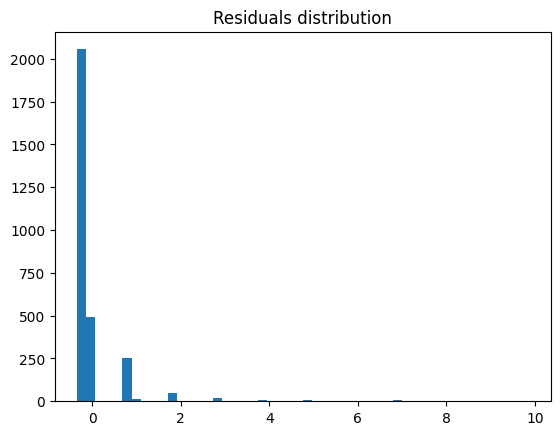

In [ ]:
residuals = y_test.to_numpy() - y_pred

plt.hist(residuals, bins=50)
plt.title("Residuals distribution")
plt.show()

Enorme pic autour de 0

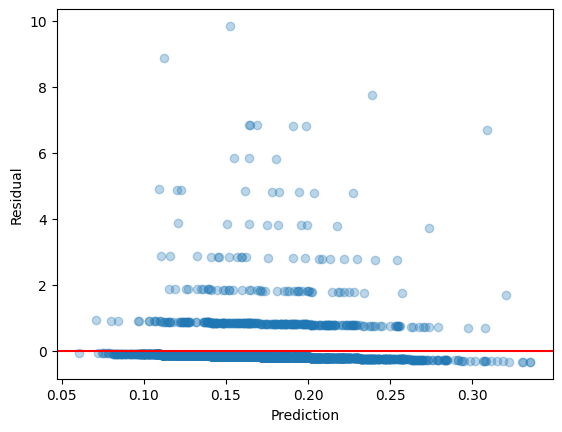

In [31]:
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Prediction")
plt.ylabel("Residual")
plt.show()

> Le modele prdit E[Y] ≈ 0.17 pour presque tout le monde

> Cependant il y a un autre phénomene dans notre dataset : beaucoup de zero 

In [32]:
(y_train == 0).mean()
# 88 % de patients avec 0 exacerbation.
# Nous avons une forte infiltration de signal de zero infiltration 

0.8886792452830189

On observe que post_index_exacerbations365 est très déséquilibré
Dans le cas ou : 
- 0 exacerbations → majorité
- 1 → quelques cas
- 2+ → très rare

Données de comptage très rares avec forte proportion de zéros.

Le modèle Poisson peut fonctionner, mais statistiquement les modèles souvent meilleurs sont :

- Zero-Inflated Poisson (ZIP)
- Negative binomiale (NB)
- Zero-Inflated Negative Binomial (ZINB)

**Zero-Inflated Poisson**

Quand il y a beaucoup trop de 0.

Dans ***zero inflated model*** , on suppose deux processus :

- certains individus ne peuvent jamais avoir d exacerbation (stables , jamais d exacerbations)= Structurels
- les autres suivent une distribution de comptage, (qui arrive rarement) , patient a risque = aléatoires

In [33]:
class ZIPRegressor(BaseEstimator, RegressorMixin):

    def __init__(self, inflation="logit", maxiter=100):
        self.inflation = inflation
        self.maxiter = maxiter
        self.model_ = None

    def fit(self, X, y):

        X = sm.add_constant(X)
        y = np.asarray(y)

        self.model_ = ZeroInflatedPoisson(
            y,
            X,
            exog_infl=X,
            inflation=self.inflation
        ).fit(maxiter=self.maxiter, disp=0)

        return self

    def predict(self, X):

        X = sm.add_constant(X)

        return self.model_.predict(
            exog=X,
            exog_infl=X
        )

zip_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", ZIPRegressor())
])

In [34]:
param_grid = {
    "model__inflation": ["logit", "probit"],
    "model__maxiter": [50, 100, 200]
}

zip_search = GridSearchCV(
    zip_pipeline,
    param_grid,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1
)

zip_search.fit(X_train, y_train)

print("Best params:", zip_search.best_params_)
print("Best deviance:", -zip_search.best_score_)

Best params: {'model__inflation': 'probit', 'model__maxiter': 50}
Best deviance: 0.7977021010038962


c:\Users\Abdo\OneDrive\Desktop\3. M1\Data Challenge 2\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [35]:
best_zip = zip_search.best_estimator_

y_pred = best_zip.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)
print("ZIP deviance :", score)

ZIP deviance : 0.9411690529757466


| modèle  | deviance |
| ------- | -------- |
|Dummy    | 0.950   |
|Poisson | **0.9400**    |
| ZIP     | 0.9411   |


> 89 % de zéros mais ZIP n’améliore rien et degrade. Cela suggère tout simplement que la conséquence d’un événement rare , plutôt que de zéros structurels

> Et ce type de phénomène est exactement ce que capture le Negative Binomial. Beaucoup de zéros, quelques événements, et une variance qui explose un peu plus que prévu.

**Negative binomiale**

Le Negative Binomial ajoute un paramètre de dispersion :

$$
Var(Y)=μ+αμ^2
$$

ce qui capture beaucoup mieux les phénomènes biologiques.

In [36]:
class NegativeBinomialRegressor(BaseEstimator, RegressorMixin):

    def __init__(self, alpha=1.0, maxiter=100):
        self.alpha = alpha
        self.maxiter = maxiter
        self.model_ = None

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        X = sm.add_constant(X)

        self.model_ = sm.GLM(
            y,
            X,
            family=sm.families.NegativeBinomial(alpha=self.alpha)
        ).fit(maxiter=self.maxiter)

        return self

    def predict(self, X):

        X = np.asarray(X)
        X = sm.add_constant(X)

        return self.model_.predict(X)

In [37]:
nb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", NegativeBinomialRegressor())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 0.5, 1, 2, 5],
    "model__maxiter": [50, 100, 200]
}

nb_search = GridSearchCV(
    nb_pipeline,
    param_grid,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1
)

nb_search.fit(X_train, y_train)

print("Best params:", nb_search.best_params_)
print("Best deviance:", -nb_search.best_score_)

Best params: {'model__alpha': 5, 'model__maxiter': 50}
Best deviance: 0.7971814205196608


In [38]:
best_nb = nb_search.best_estimator_

y_pred = best_nb.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)

print("NB deviance :", score)

NB deviance : 0.9408073733438522


| modèle  | deviance |
| ------- | -------- |
|Dummy    | ~0.950   |
|Poisson | ~**0.9400** |
| ZIP     | ~0.9411   |
| NB      | 0.9408|


**Zero-Inflated Negative Binomial.**

Zero-Inflated Negative Binomial combine : 
- inflation des zéros
- dispersion supplémentaire


In [39]:
class ZINBRegressor(BaseEstimator, RegressorMixin):

    def __init__(self, inflation="logit", maxiter=100, p=2):
        self.inflation = inflation
        self.maxiter = maxiter
        self.p = p
        self.model_ = None

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)

        X = sm.add_constant(X)

        self.model_ = ZeroInflatedNegativeBinomialP(
            y,
            X,
            exog_infl=X,
            inflation=self.inflation,
            p=self.p
        ).fit(maxiter=self.maxiter, disp=0)

        return self

    def predict(self, X):

        X = np.asarray(X)
        X = sm.add_constant(X)

        return self.model_.predict(
            exog=X,
            exog_infl=X
        )

In [40]:
zinb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", ZINBRegressor())
])

param_grid = {
    "model__inflation": ["logit", "probit"],
    "model__maxiter": [50, 100, 200],
    "model__p": [1, 2]
}

zinb_search = GridSearchCV(
    zinb_pipeline,
    param_grid,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1
)

zinb_search.fit(X_train, y_train)

print("Best params:", zinb_search.best_params_)
print("Best deviance:", -zinb_search.best_score_)

c:\Users\Abdo\OneDrive\Desktop\3. M1\Data Challenge 2\.venv\Lib\site-packages\sklearn\model_selection\_search.py:1137: UserWarning: One or more of the test scores are non-finite: [-0.79645198 -0.79869016 -0.79774104 -0.79928379 -0.80212251 -0.80128522
 -0.79717074 -0.79916258 -0.79941007 -0.80070633         nan -0.80171388]
  warnings.warn(


Best params: {'model__inflation': 'logit', 'model__maxiter': 50, 'model__p': 1}
Best deviance: 0.7964519802248139


c:\Users\Abdo\OneDrive\Desktop\3. M1\Data Challenge 2\.venv\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
c:\Users\Abdo\OneDrive\Desktop\3. M1\Data Challenge 2\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [41]:
best_zinb = zinb_search.best_estimator_

y_pred = best_zinb.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)

print("ZINB deviance :", score)

ZINB deviance : 0.9430192995930917


| modèle  | deviance |
| ------- | -------- |
|Dummy    | ~0.950   |
|Poisson | ~**0.9400** |
| ZIP     | ~0.9411   |
| NB      | 0.9408|
| ZINB    | 0.9430   |



> Le modèle de Poisson obtient la plus faible déviance parmi les modèles testés elle décrit déjà assez bien la dispersion des données. 

> Les modèles ZIP et Negative Binomial n’apportent aussi pas d’amélioration significative, ce qui suggère que la distribution des données est bien capturée par un processus de Poisson simple, sans forte inflation de zéros ni surdispersion marquée.

Notre dataset a :
- ~89 % de zéros : les zéros semblent plutôt être des événement rare mais possible
- moyenne ≈ 0.17
- variance ≈ 0.37

### 5. Modele d ensemble pour le compatage

On peux essayer des arbres de gradient boosting pour données de comptage :

- HistGradientBoostingRegressor(loss="poisson")
- XGBoost poisson

Ces modèles gèrent mieux la dispersion des données médicales.

Le principe scientifique derrière ces deux modèles sont: au lieu d’ajuster une relation linéaire

$$
log(λ)=Xβ
$$

comme dans un GLM, ils apprennent une fonction non linéaire complexe :

$$
log(λ)=f(X)
$$

où 
f(X) est construit par une somme d’arbres de décision.

Les arbres capturent automatiquement :

- interactions entre variables
- effets non linéaires

ce que Poisson ou NB capturent mal.

**HistGradientBoostingRegressor(loss="poisson")**

HistGradientBoostingRegressor combine :
- arbres de décision
- gradient boosting
- loss poisson

In [42]:
hgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", HistGradientBoostingRegressor(
        loss="poisson",
        random_state=42
    ))
])

| paramètre       | effet                       |
| --------------- | --------------------------- |
| max_iter ↑      | modèle plus complexe        |
| learning_rate ↓ | plus stable                 |
| max_depth ↑     | interactions plus complexes |


In [43]:
search_spaces = {
    "model__max_iter": Integer(100, 400),
    "model__learning_rate": Real(0.01, 0.2, prior="log-uniform"),
    "model__max_depth": Integer(3, 10),
    "model__min_samples_leaf": Integer(10, 150),
    "model__l2_regularization": Real(0.0, 2.0),
}
hgb_search = BayesSearchCV(
    estimator=hgb_pipeline,
    search_spaces=search_spaces,
    n_iter=50,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1,
    random_state=42
)

hgb_search.fit(X_train, y_train)

print("Best params:", hgb_search.best_params_)
print("Best deviance:", -hgb_search.best_score_)

Best params: OrderedDict({'model__l2_regularization': 2.0, 'model__learning_rate': 0.025851986856579672, 'model__max_depth': 3, 'model__max_iter': 100, 'model__min_samples_leaf': 10})
Best deviance: 0.7968116376669485


In [44]:
best_hgb = hgb_search.best_estimator_
y_pred = best_hgb.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)

print("HGB deviance :", score)

HGB deviance : 0.9376281134601366


| modèle  | deviance |
| ------- | -------- |
|Dummy    | ~0.950   |
|Poisson | ~0.9400 |
| ZIP     | ~0.9411   |
| NB      | 0.9408|
| ZINB    | 0.9430   |
| HGB    | **0.9376**   |

> Le HistGradientBoostingRegressor obtient la plus faible déviance et devient le modèle le plus performant. Cela suggère que les relations entre les variables et le nombre d’exacerbations sont légèrement non linéaires, mieux capturées par un modèle d’ensemble que par les modèles de comptage classiques.

**XGBoost avec objectif Poisson**

In [45]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", XGBRegressor(
        objective="count:poisson",
        random_state=42
    ))
])

search_spaces = {
    "model__n_estimators": Integer(100, 400),
    "model__max_depth": Integer(3, 10),
    "model__learning_rate": Real(0.01, 0.2, prior="log-uniform"),
    "model__subsample": Real(0.6, 1.0),
    "model__colsample_bytree": Real(0.6, 1.0),
    "model__min_child_weight": Integer(1, 10),
}

xgb_search = BayesSearchCV(
    estimator=xgb_pipeline,
    search_spaces=search_spaces,
    n_iter=50,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1,
    random_state=42
)

xgb_search.fit(X_train, y_train)

print("Best params:", xgb_search.best_params_)
print("Best deviance:", -xgb_search.best_score_)

Best params: OrderedDict({'model__colsample_bytree': 0.6934177266017714, 'model__learning_rate': 0.028465471052123954, 'model__max_depth': 3, 'model__min_child_weight': 1, 'model__n_estimators': 169, 'model__subsample': 0.8622326064621375})
Best deviance: 0.7949239611625671


In [46]:
best_xgb = xgb_search.best_estimator_

y_pred = best_xgb.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)
print("XGB deviance :", score)

XGB deviance : 0.9313604831695557


| modèle  | deviance |
| ------- | -------- |
|Dummy    | ~0.950   |
|Poisson | ~0.9400 |
| ZIP     | ~0.9411   |
| NB      | 0.9408|
| ZINB    | 0.9430   |
| HGB    | 0.9376   |
| XGBPoisson      | **0.9313**|


> XGBoost Poisson obtient la meilleure performance, confirmant l’avantage des méthodes de boosting pour capturer les interactions et non-linéarités du phénomène.

### 5. (hurdle model ou two-part model) 

Ce modèle suppose que le processus réel est :

- processus binaire : l'exacerbation arrive ou non
- processus de comptage : combien d'exacerbations chez les patients malades

Un détail amusant sur ce type de modèle.
> Dans les années 1980, les statisticiens ont inventé les modèles hurdle pour modéliser les visites à l’hôpital. L’idée était exactement celle que tu implémentes ici :

- franchir la barrière zéro (aucun événement)
- puis modéliser l’intensité de l’événement

> Le machine learning moderne redécouvre la même idée avec des outils plus flexibles (gradient boosting, random forests, etc.). Les mathématiques restent les mêmes, seules les machines ont changé.

In [47]:
class TwoStageModel(BaseEstimator, RegressorMixin):

    def __init__(self, clf, reg):
        self.clf = clf
        self.reg = reg

    def fit(self, X, y):

        y = np.asarray(y)

        # étape 1 : classification
        y_binary = (y > 0).astype(int)
        self.clf.fit(X, y_binary)

        # étape 2 : régression sur les cas positifs
        mask = y > 0
        X_pos = X[mask]
        y_pos = y[mask]

        self.reg.fit(X_pos, y_pos)

        # flag que sklearn attend
        self.is_fitted_ = True

        return self

    def predict(self, X):

        p = self.clf.predict_proba(X)[:,1]
        count = self.reg.predict(X)

        return p * count

In [48]:
model = TwoStageModel(
    HistGradientBoostingClassifier(
    max_depth=5,
    learning_rate=0.05,
    max_iter=200,
    random_state=42
),
    HistGradientBoostingRegressor(
    loss="poisson",
    max_depth=5,
    learning_rate=0.05,
    max_iter=200,
    random_state=42
)
)

two_stage = Pipeline([
    ("preprocessor", preprocessor),
    ("remove_constant", VarianceThreshold(0.0)),
    ("model", model)
])

param_space = {
    "model__clf__max_depth": Integer(3,7),
    "model__clf__learning_rate": Real(0.01,0.1),
    "model__clf__max_iter": Integer(100,400),
    "model__clf__min_samples_leaf": Integer(20,100),

    "model__reg__max_depth": Integer(3,7),
    "model__reg__learning_rate": Real(0.01,0.1),
    "model__reg__max_iter": Integer(100,400),
    "model__reg__min_samples_leaf": Integer(20,100)
}

opt = BayesSearchCV(
    two_stage,
    param_space,
    n_iter=40,
    cv=5,
    scoring=make_scorer(mean_poisson_deviance, greater_is_better=False),
    n_jobs=-1,
    random_state=42
)

opt.fit(X_train, y_train)

print("Best params:", opt.best_params_)
print("Best deviance:", -opt.best_score_)

Best params: OrderedDict({'model__clf__learning_rate': 0.01, 'model__clf__max_depth': 3, 'model__clf__max_iter': 100, 'model__clf__min_samples_leaf': 65, 'model__reg__learning_rate': 0.01, 'model__reg__max_depth': 3, 'model__reg__max_iter': 100, 'model__reg__min_samples_leaf': 20})
Best deviance: 0.7963354791079305


In [49]:
best_two_stage = opt.best_estimator_

y_pred = best_two_stage.predict(X_test)
score = mean_poisson_deviance(y_test, y_pred)

print("TwoStage deviance :", score)

TwoStage deviance : 0.9382709102754055


| modèle  | deviance |
| ------- | -------- |
|Dummy    | ~0.950   |
|Poisson | ~0.9400 |
| ZIP     | ~0.9411   |
| NB      | 0.9408|
| ZINB    | 0.9430   |
| HGB    | 0.9376   |
| XGBPoisson      | **0.9313**|
|TwoStageModel|0.9382      |


> Les modèles de comptage classiques basés sur les GLM (Poisson, NB, ZIP, ZINB) ont des performances très proches (~0.94), ce qui indique que la limite principale n’est pas la distribution mais la relation linéaire entre variables et cible.
Les modèles basés sur les arbres capturent mieux les interactions non linéaires ainsi que notre modele twostagemodel, d’où de meilleures performances.
Le XGBRegressor avec objectif Poisson obtient la plus faible deviance (0.9313) et est donc choisi comme modèle final.

## Prediction file 

Dans notre dataset 
- beaucoup de patients sont stables pendant l’année
- quelques patients font 1 ou 2 exacerbations

In [50]:
type(best_xgb)

sklearn.pipeline.Pipeline

In [51]:
# récupérer le meilleur modèle
final_model = best_xgb
# Sauvegarder dans le dossier models 
joblib.dump(final_model, "../../models/final_model.pkl")

['../../models/final_model.pkl']

In [52]:
# Charger le modèle
model = joblib.load("../../models/final_model.pkl")

patid = df["patid"]
X_new = df.drop("patid")

# prédiction
prediction = model.predict(X_new)

# convertir en entier
#yprediction = np.round(prediction).astype(int)
prediction = np.floor(prediction).astype(int)
prediction

array([0, 0, 0, ..., 0, 0, 0], shape=(14575,))

In [ ]:
result = pl.DataFrame({
    "patid": patid,
    "prediction": prediction
})

result.write_csv("../../outputs/predictions_nbre_exacerbation.csv")

print("Fichier outputs/Grp3_abdo_louise_flora_predictions_nbre_exacerbation.csv généré avec succès.")

Fichier outputs/predictions_nbre_exacerbation.csv généré avec succès.
